# The double well

A particle in a symmetric double well has its lowest states in nearly degenerate pairs: an even
state $\varphi_0$ and an odd state $\varphi_1$, split by a tiny energy $\Delta = E_1 - E_0$. Their sum
and difference are localized in the left and the right well, so a particle placed in one well
tunnels back and forth with period $2\pi/\Delta$, although classically it could never cross the
barrier. Ammonia's inversion line, the basis of the first maser, is such a splitting.

This notebook finds the splitting in three ways (eigenstates, tunneling oscillation, spectrum),
drives a Rabi oscillation between the two states, and shows *coherent destruction of tunneling*:
a fast periodic force of the right strength freezes the particle in its well (Grossmann, Dittrich,
Jung and Hänggi, Phys. Rev. Lett. **67**, 516 (1991)).

In [1]:
# On Colab or JupyterLite (or anywhere without the package), install it first:
try:
    import so_schroedinger  # noqa: F401
except ImportError:
    import sys

    if sys.platform == "emscripten":  # JupyterLite: the package comes with the site
        %pip install so_schroedinger
    else:
        %pip install -q git+https://github.com/aeberspaecher/splitoperator

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from scipy.special import j0, jn_zeros

import so_schroedinger as so

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["figure.dpi"] = 72

## Potential and eigenstates

The quartic double well $V(x) = V_0\,(x^2/a^2 - 1)^2$ has minima at $x = \pm a$ and a barrier of height
$V_0$ at $x = 0$. An optional force $F\cos(\omega t)$ adds $F x\cos(\omega t)$ for the later sections.
The lowest eigenstates come from imaginary time evolution with `so.lowest_eigenstates`. They have
arbitrary complex phases, which we remove to make them real.

energies: [1.9567 1.9997 4.8666 5.7411]
splitting Delta = E1 - E0 = 0.0430, tunneling period 2 pi/Delta = 146
second doublet: E3 - E2 = 0.875


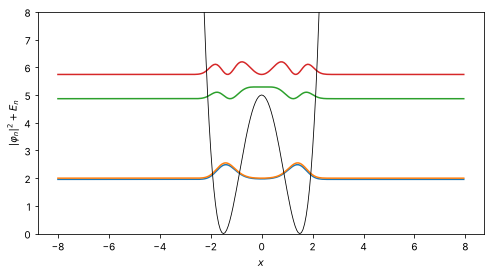

In [3]:
class DoubleWell(so.Potential1d):
    """V0 (x^2/a^2 - 1)^2 + F x cos(omega t)."""

    def __init__(self, V0, a, force=0.0, omega=0.0):
        self.V0, self.a, self.F, self.omega = V0, a, force, omega
        self.is_time_dependent = force != 0.0

    def V(self, x, t):
        x = np.asarray(x)
        return self.V0 * ((x / self.a) ** 2 - 1) ** 2 + self.F * x * np.cos(self.omega * t) + 0.0j


V0, a = 5.0, 1.5
size, N = (-8.0, 8.0), 256
grid = so.Grid1d(size, N, DoubleWell(V0, a), so.Gaussian1d(-a, 0.5, 0.0))
x = grid.x_vals
energies, states = so.lowest_eigenstates(grid, 4, dt=0.02, tol=1e-12, rng=0)
states = [phi * np.exp(-1j * np.angle(phi[np.argmax(np.abs(phi))])) for phi in states]  # make them real
Delta = energies[1] - energies[0]

so.plotting.plot_eigenstates(grid, states, energies, scale=1.0)
plt.ylim(0, 8)
print("energies:", np.round(energies, 4))
print(f"splitting Delta = E1 - E0 = {Delta:.4f}, tunneling period 2 pi/Delta = {2 * np.pi / Delta:.0f}")
print(f"second doublet: E3 - E2 = {energies[3] - energies[2]:.3f}")

The second doublet lies closer to the barrier top and is split much more: the splitting grows
roughly exponentially with energy, as the WKB tunneling factor $e^{-\int|p|\,dx}$ through the
barrier does.

## Tunneling

$\psi_L = (\varphi_0 - \varphi_1)/\sqrt{2}$ (with the sign of $\varphi_1$ chosen so that $\psi_L$ sits in
the left well) evolves into $(\varphi_0 - e^{-i\Delta t}\varphi_1)/\sqrt{2}$ up to a phase, which is in the
right well at $t = \pi/\Delta$. Its mean position is $\langle x\rangle = -x_0\cos(\Delta t)$ with
$x_0 = |\langle\varphi_0|x|\varphi_1\rangle|$.

In [4]:
phi0, phi1 = states[0], states[1]
x01 = np.real(np.sum(np.conj(phi0) * x * phi1) * grid.dx)
if x01 < 0:  # make phi0 - phi1 the left state
    phi1 = -phi1
x0 = abs(x01)
psi_left = (phi0 - phi1) / np.sqrt(2)

grid.psi = psi_left.copy()  # a copy: the propagation changes grid.psi in place
dt = 0.05
anim = so.animate1d(grid, so.SplitOperator(), dt, n_frames=60, steps_per_frame=int(np.pi / Delta / dt / 30))
HTML(anim.to_jshtml())

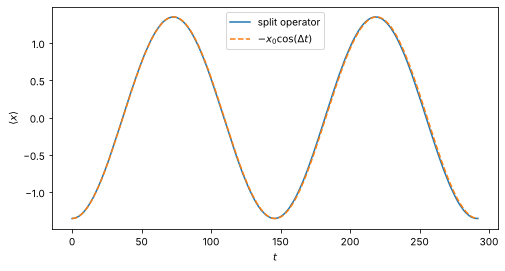

In [5]:
grid = so.Grid1d(size, N, DoubleWell(V0, a), so.Gaussian1d(-a, 0.5, 0.0))
grid.psi = psi_left.copy()
obs = so.analyzers.Observables()
obs(grid)
so.SplitOperator().propagate(grid, dt, int(4 * np.pi / Delta / dt), callback=obs, every=10)

plt.plot(obs.t, obs.position, label="split operator")
plt.plot(obs.t, -x0 * np.cos(Delta * obs.t), "--", label=r"$-x_0\cos(\Delta t)$")
plt.xlabel("$t$")
plt.ylabel(r"$\langle x\rangle$")
plt.legend();

## The splitting in the spectrum

Without knowing the eigenstates, the splitting shows up in the spectrum of the autocorrelation
function $C(t) = \langle\psi(0)|\psi(t)\rangle$ of any state that overlaps with both states of a
doublet, e.g. a Gaussian in the left well. To resolve two lines a distance $\Delta$ apart, the
propagation has to be longer than a few tunneling periods $2\pi/\Delta$, since the resolution of the
spectrum is $2\pi/T$. Here $T$ is twelve tunneling periods.

splitting from the spectrum: 0.0430 (eigenstates: 0.0430), resolution 0.0036


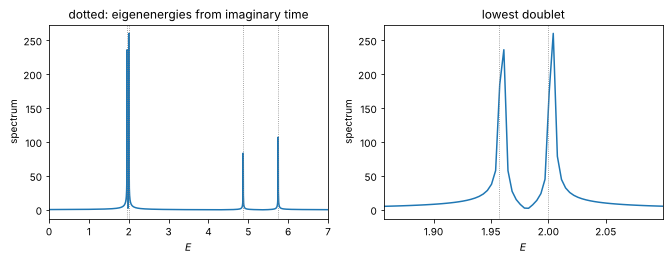

In [6]:
grid = so.Grid1d(size, N, DoubleWell(V0, a), so.Gaussian1d(-a - 0.3, 0.4, 0.0))
corr = so.analyzers.AutoCorrelation()
corr(grid)
so.SplitOperator().propagate(grid, dt, int(12 * 2 * np.pi / Delta / dt), callback=corr, every=2)
E, spectrum = corr.spectrum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, xlim in [(ax1, (0, 7)), (ax2, (energies[0] - 0.1, energies[1] + 0.1))]:
    ax.plot(E, spectrum)
    for En in energies:
        ax.axvline(En, color="gray", ls=":", lw=0.8)
    ax.set(xlim=xlim, xlabel="$E$", ylabel="spectrum")
ax1.set_title("dotted: eigenenergies from imaginary time")
ax2.set_title("lowest doublet")


def peak(E_min, E_max):
    window = (E > E_min) & (E < E_max)
    return E[window][np.argmax(spectrum[window])]


middle = energies[:2].mean()
splitting = peak(middle, middle + Delta) - peak(middle - Delta, middle)
print(f"splitting from the spectrum: {splitting:.4f} (eigenstates: {Delta:.4f}), resolution {E[1] - E[0]:.4f}")

## Rabi oscillations

A weak force $F x\cos(\omega t)$ couples $\varphi_0$ and $\varphi_1$ through the matrix element
$\langle\varphi_0|x|\varphi_1\rangle = \pm x_0$. Driven at resonance, $\omega = \Delta$, the population moves
completely from $\varphi_0$ to $\varphi_1$ and back. In the rotating wave approximation, valid for
$F x_0 \ll \Delta$, the population of $\varphi_1$ is $\sin^2(\Omega t/2)$ with the Rabi frequency $\Omega = F x_0$.
Off resonance the oscillation is faster and incomplete, with amplitude $\Omega^2/(\Omega^2 + \delta^2)$ for
a detuning $\delta = \omega - \Delta$.

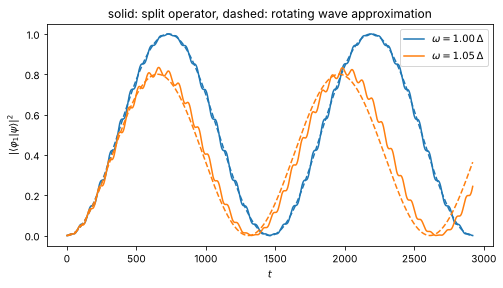

In [7]:
F = 0.1 * Delta / x0  # Rabi frequency Omega = Delta / 10
Omega = F * x0
t_max = 2 * 2 * np.pi / Omega


def excited_population(omega):
    """|<phi1|psi(t)>|^2 for a start in phi0, driven at frequency omega."""
    grid = so.Grid1d(size, N, DoubleWell(V0, a, F, omega), so.Gaussian1d(-a, 0.5, 0.0))
    grid.psi = phi0.copy()
    t, p1 = [], []
    record = lambda g: (t.append(g.t), p1.append(abs(np.sum(np.conj(phi1) * g.psi) * g.dx) ** 2))
    record(grid)
    so.SplitOperator().propagate(grid, dt, int(t_max / dt), callback=record, every=20)
    return np.array(t), np.array(p1)


for omega in [Delta, 1.05 * Delta]:
    t, P1 = excited_population(omega)
    delta = omega - Delta
    W = np.hypot(Omega, delta)
    line = plt.plot(t, P1, label=f"$\\omega = {omega / Delta:.2f}\\,\\Delta$")[0]
    plt.plot(t, (Omega / W) ** 2 * np.sin(W * t / 2) ** 2, "--", color=line.get_color())
plt.xlabel("$t$")
plt.ylabel(r"$|\langle\varphi_1|\psi\rangle|^2$")
plt.title("solid: split operator, dashed: rotating wave approximation")
plt.legend();

The small wiggles come from the counter-rotating part of the drive, which the rotating wave
approximation drops; it also shifts the resonance slightly (Bloch–Siegert shift), so the detuned
curve drifts away from the prediction over time.

## Coherent destruction of tunneling

Now drive fast, $\omega \gg \Delta$, but still well below the gap to the second doublet. In the two
state picture, the force shifts the left and the right state by $\mp F x_0\cos(\omega t)$. Averaged over a
drive period, tunneling continues with an effective splitting

$$\Delta_\mathrm{eff} = \Delta\, J_0\!\left(\frac{2 F x_0}{\omega}\right),$$

which vanishes at the zeros of the Bessel function $J_0$. There the particle stays in the well it
started in, although the force is strong and pushes it back and forth. We start in $\psi_L$ and drive
with $\omega = 10\,\Delta$, once with the force tuned to the first zero of $J_0$, $2Fx_0/\omega = 2.405$.

F at the first zero of J0: 0.383


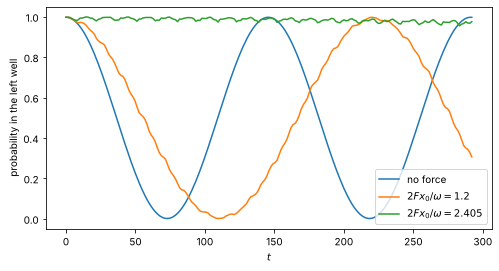

In [8]:
omega = 10 * Delta


def left_probability(force, t_max, n_samples=200):
    """Probability in the left well at n_samples times up to exactly t_max."""
    grid = so.Grid1d(size, N, DoubleWell(V0, a, force, omega), so.Gaussian1d(-a, 0.5, 0.0))
    grid.psi = psi_left.copy()
    every = int(np.ceil(t_max / dt / n_samples))
    t, p_left = [], []
    record = lambda g: (t.append(g.t), p_left.append(np.sum(g.density[x < 0]) * g.dx))
    record(grid)
    so.SplitOperator().propagate(grid, t_max / (every * n_samples), every * n_samples, callback=record, every=every)
    return np.array(t), np.array(p_left)


F_cdt = jn_zeros(0, 1)[0] * omega / (2 * x0)
for F, label in [(0.0, "no force"), (0.5 * F_cdt, r"$2Fx_0/\omega = 1.2$"), (F_cdt, r"$2Fx_0/\omega = 2.405$")]:
    t, P_left = left_probability(F, 4 * np.pi / Delta)
    plt.plot(t, P_left, label=label)
plt.xlabel("$t$")
plt.ylabel("probability in the left well")
plt.legend()
print(f"F at the first zero of J0: {F_cdt:.3f}")

Without the force, the particle tunnels completely to the right well and back. Half way to the zero
it tunnels more slowly, and at the zero it stays left, apart from small wiggles at the drive
frequency.

The probability in the left well after the time $\pi/\Delta$, at which the undriven particle has
tunneled completely, measures $\Delta_\mathrm{eff}$: in the two state picture it is
$\cos^2(\pi\Delta_\mathrm{eff}/2\Delta)$. The time $\pi/\Delta$ is five drive periods, so the comparison is
stroboscopic and free of the micromotion.

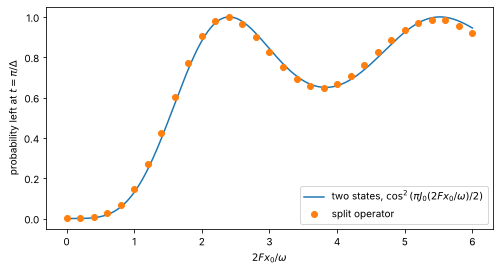

In [9]:
F_scan = np.linspace(0, 6.0, 31) * omega / (2 * x0)
P_end = [left_probability(F, np.pi / Delta, n_samples=1)[1][-1] for F in F_scan]

s = np.linspace(0, 6.0, 300)
plt.plot(s, np.cos(np.pi * j0(s) / 2) ** 2, label=r"two states, $\cos^2(\pi J_0(2Fx_0/\omega)/2)$")
plt.plot(F_scan * 2 * x0 / omega, P_end, "o", label="split operator")
plt.xlabel(r"$2Fx_0/\omega$")
plt.ylabel(r"probability left at $t = \pi/\Delta$")
plt.legend();

The split operator results follow the two state prediction closely, with maxima at both zeros of
$J_0$, 2.405 and 5.520. Small deviations appear at strong forcing, where $F x_0$ approaches the gap
to the second doublet and the drive starts to mix in higher states, which the two state picture
leaves out.

Things to try:

* Make the barrier higher (`V0`) and watch the splitting drop exponentially.
* Drive at the second doublet's resonance, $\omega = E_3 - E_2$, or at $E_2 - E_1$, which needs a
  stronger force because the matrix element is smaller.
* Break the symmetry with a static tilt, `F * x` with `omega = 0`: the tunneling becomes incomplete.